# E01 · 道路图像处理 V2.0

## 00 · 环境与素材
同一张真实道路图片只修改一个参数，比较处理前后差异。

In [1]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
def locate_images():
    here=Path.cwd().resolve()
    for root in [here,*here.parents]:
        p=root/'images'
        if (p/'01_solidWhiteRight_straight_white.jpg').exists(): return p
    kaggle=Path('/kaggle/input')
    if kaggle.exists():
        for p in kaggle.glob('**/images/01_solidWhiteRight_straight_white.jpg'): return p.parent
    raise FileNotFoundError('请解压完整教学包，确保 images/ 与 Notebook 一同提供')
IMAGES=locate_images()
def read(name):
    x=cv2.imread(str(IMAGES/name))
    if x is None: raise FileNotFoundError(name)
    return x
def view(items):
    fig,axs=plt.subplots(1,len(items),figsize=(5*len(items),4))
    if len(items)==1: axs=[axs]
    for ax,(name,img) in zip(axs,items):
        ax.imshow(img if img.ndim==2 else cv2.cvtColor(img,cv2.COLOR_BGR2RGB),cmap='gray' if img.ndim==2 else None)
        ax.set_title(name);ax.axis('off')
    plt.tight_layout();plt.show()
print('Image path:',IMAGES,'OpenCV:',cv2.__version__)


Image path: /home/runner/work/multimodal-document-ai-learning-center/multimodal-document-ai-learning-center/docs/resources/course-labs/intelligent-perception/images OpenCV: 5.1.0


## 01 · 探索实验一：RGB / HSV 颜色空间
探索黄线和白线为什么需要不同的阈值。

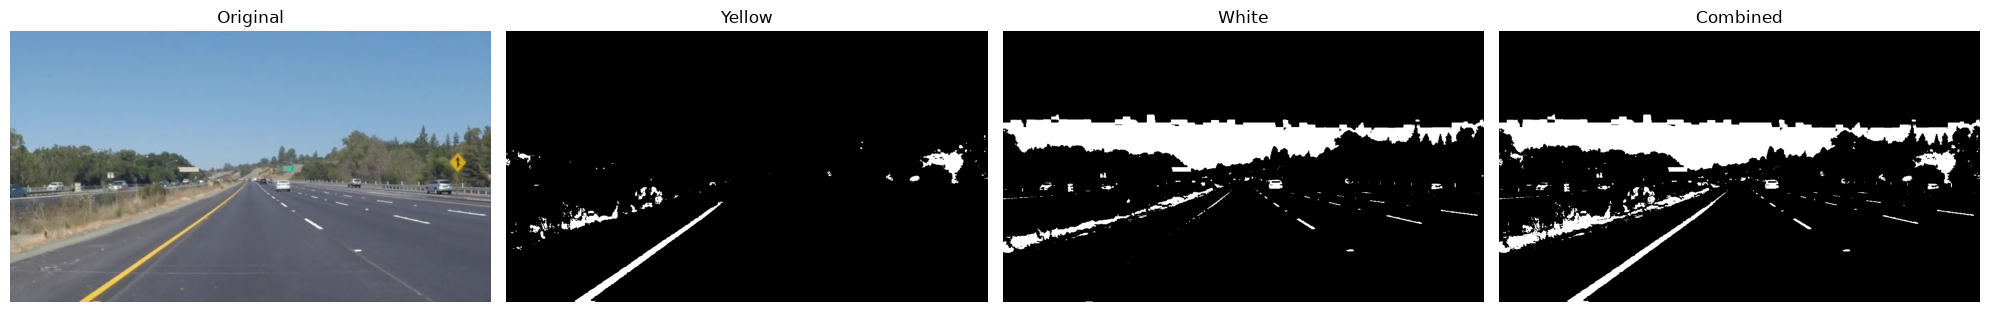

In [2]:
img=read('02_solidYellowLeft_yellow_white.jpg')
hsv=cv2.cvtColor(img,cv2.COLOR_BGR2HSV)
yellow=cv2.inRange(hsv,(15,70,70),(40,255,255))
white=cv2.inRange(hsv,(0,0,175),(179,85,255))
view([('Original',img),('Yellow',yellow),('White',white),('Combined',cv2.bitwise_or(yellow,white))])


### 探索任务 1 · HSV 阈值实验 Cell
先预测：调整黄色 H 范围时，车道线与背景会怎样变化？
1. 仅修改黄色色调下限 5、15、25。
2. 对比误检、漏检，记录颜色阈值的适用条件。
3. 思考白色天空为何可能被当成白线。

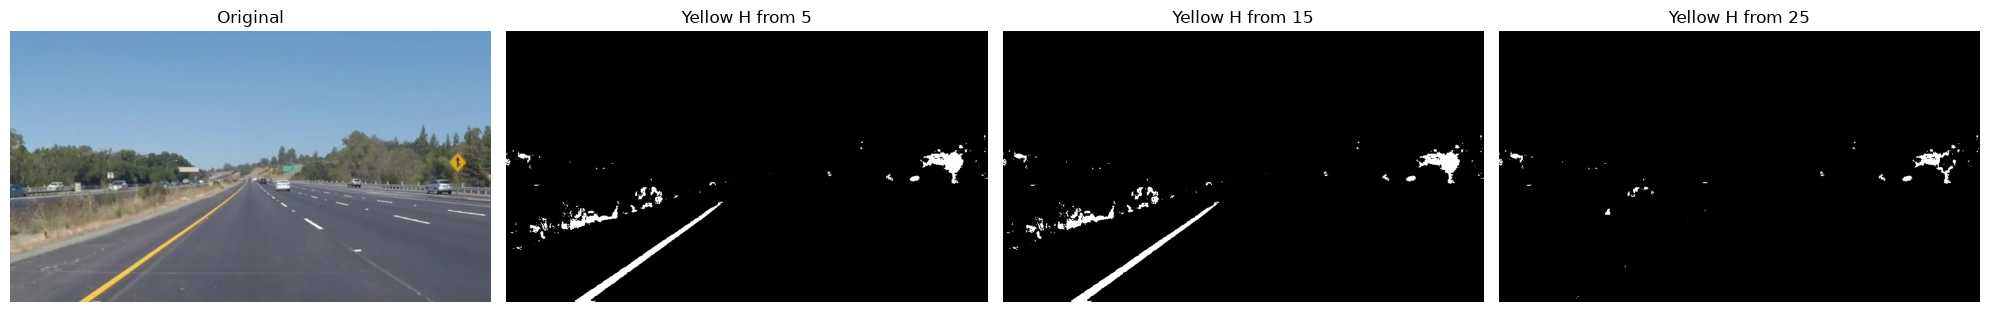

In [3]:
img=read('02_solidYellowLeft_yellow_white.jpg')
hsv=cv2.cvtColor(img,cv2.COLOR_BGR2HSV)
view([('Original',img)]+[(f'Yellow H from {lo}',cv2.inRange(hsv,(lo,70,70),(40,255,255))) for lo in (5,15,25)])

## 02 · 探索实验二：阈值方法
同一阈值为什么无法适应所有亮度？

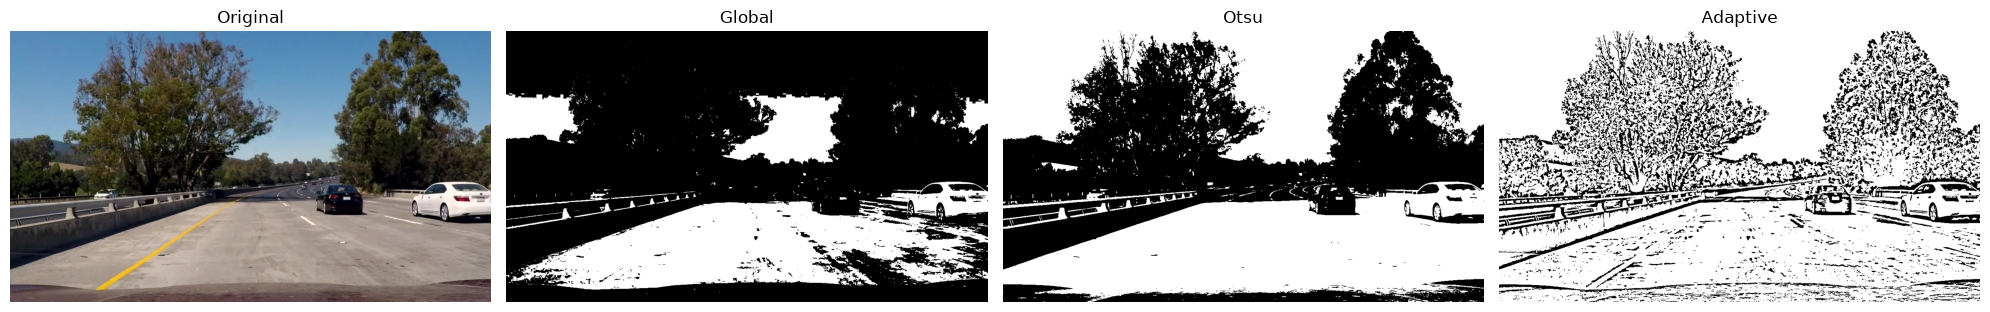

In [4]:
img=read('06_challenge_bright_pavement.jpg')
g=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
_,a=cv2.threshold(g,150,255,cv2.THRESH_BINARY)
_,b=cv2.threshold(g,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
c=cv2.adaptiveThreshold(g,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,31,7)
view([('Original',img),('Global',a),('Otsu',b),('Adaptive',c)])


### 探索任务 2 · 阈值实验 Cell
先预测：全局阈值增大，车道标线是否一定更准确？
1. 固定素材，比较阈值 100、150、200。
2. 找到误检增加和细节丢失的位置。
3. 讨论阴影图像为何适用不同设置。

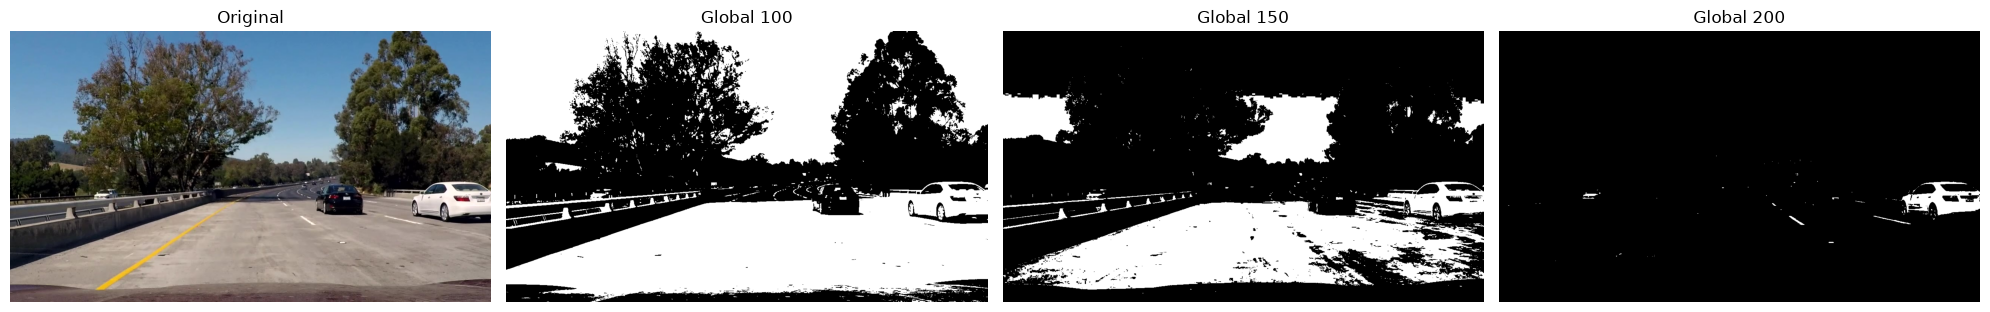

In [5]:
img=read('06_challenge_bright_pavement.jpg')
g=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
view([('Original',img)]+[(f'Global {t}',cv2.threshold(g,t,255,cv2.THRESH_BINARY)[1]) for t in (100,150,200)])

## 03 · 探索实验三：滤波与 CLAHE
对比高斯、中值和双边滤波。

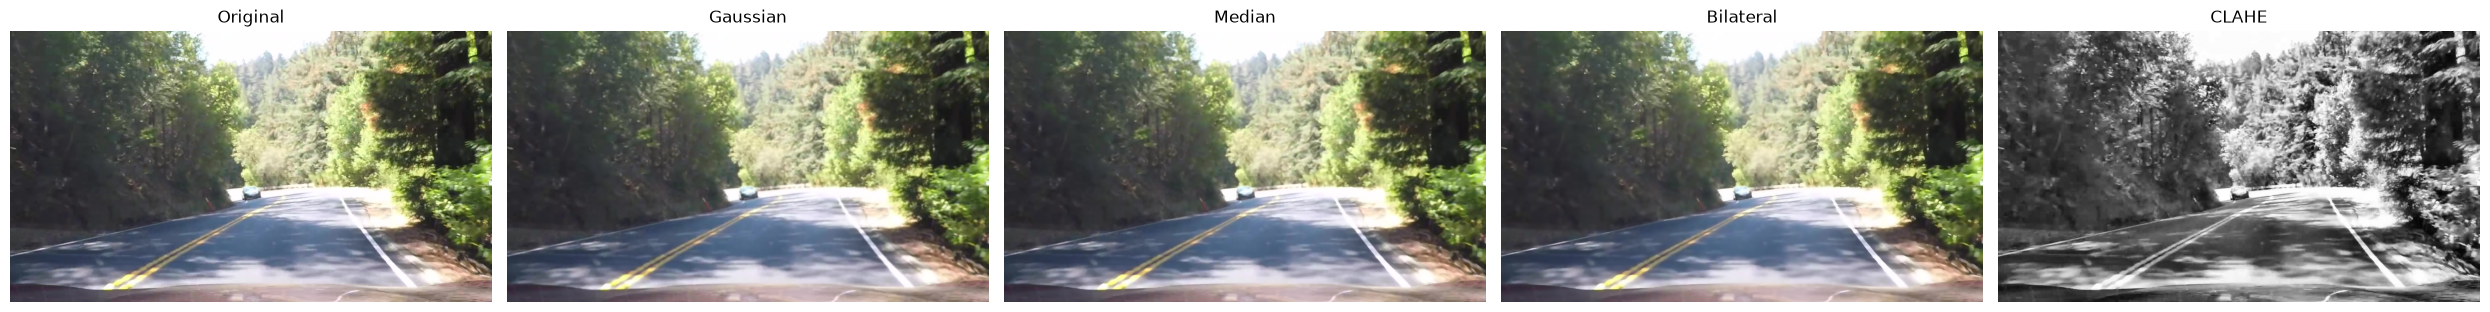

In [6]:
img=read('08_harder_shadow_glare.jpg')
g=cv2.GaussianBlur(img,(5,5),1.2);m=cv2.medianBlur(img,5)
b=cv2.bilateralFilter(img,9,60,60)
c=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(cv2.cvtColor(img,cv2.COLOR_BGR2GRAY))
view([('Original',img),('Gaussian',g),('Median',m),('Bilateral',b),('CLAHE',c)])


### 探索任务 3 · 滤波实验 Cell
先预测：核越大，噪声减少的同时会发生什么？
1. 比较 Gaussian 核 3、5、9。
2. 观察标线边缘、道路纹理。
3. 解释过度平滑与边缘保留的矛盾。

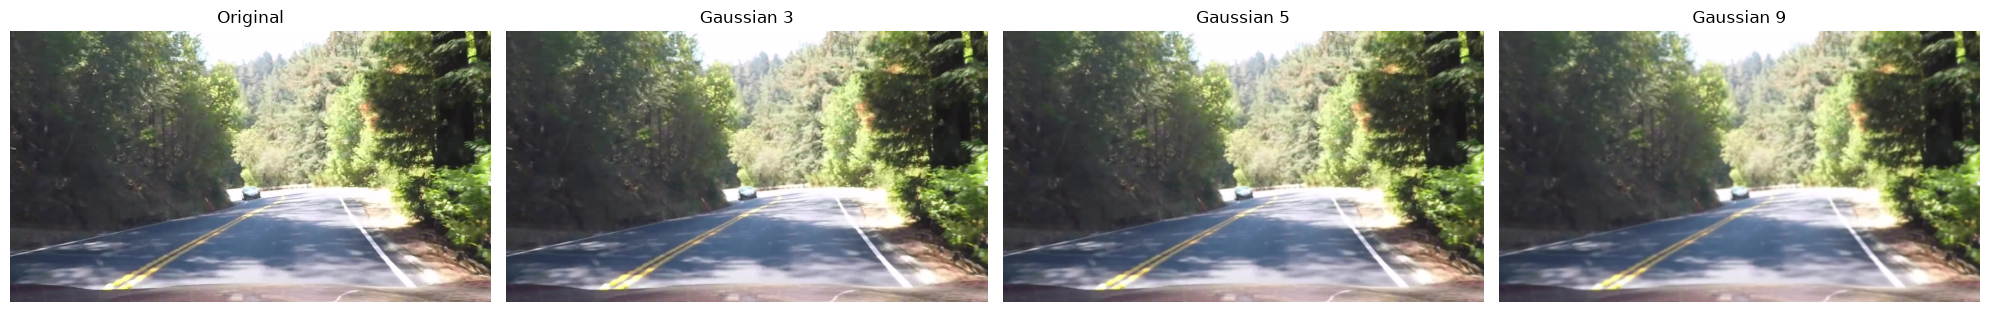

In [7]:
img=read('08_harder_shadow_glare.jpg')
view([('Original',img)]+[(f'Gaussian {k}',cv2.GaussianBlur(img,(k,k),0)) for k in (3,5,9)])

## 04 · 探索实验四：形态学
腐蚀、膨胀、开运算、闭运算有什么不同？

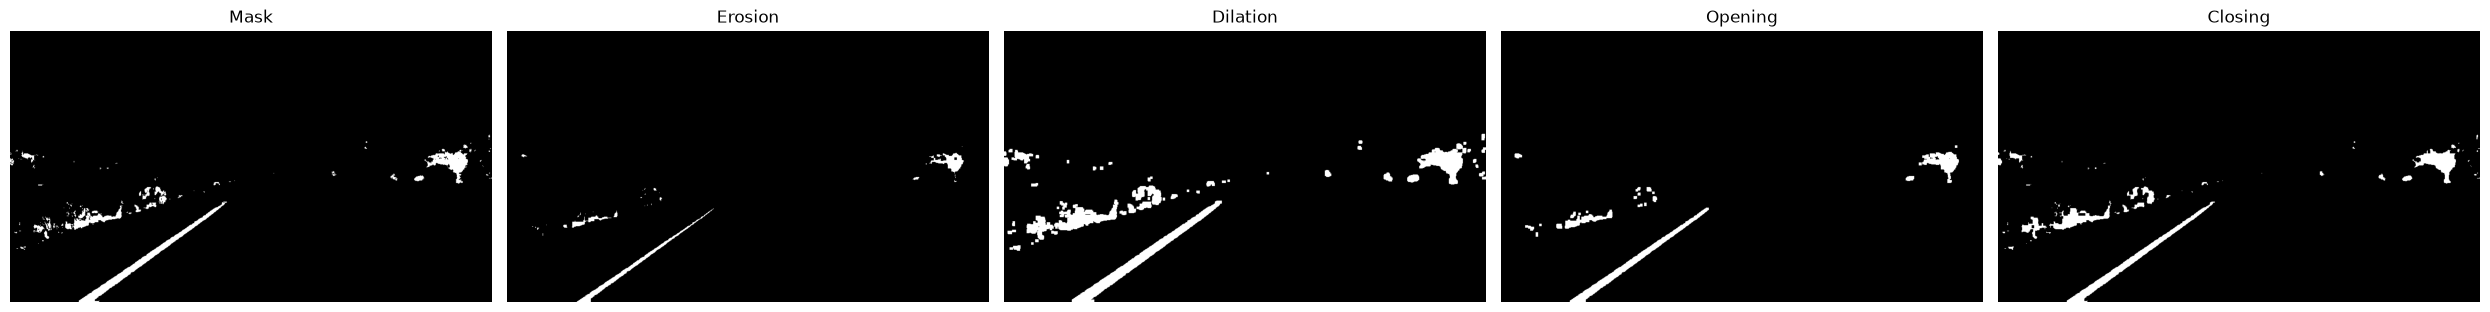

In [8]:
img=read('02_solidYellowLeft_yellow_white.jpg')
mask=cv2.inRange(cv2.cvtColor(img,cv2.COLOR_BGR2HSV),(15,70,70),(40,255,255))
k=cv2.getStructuringElement(cv2.MORPH_RECT,(5,5))
view([('Mask',mask),('Erosion',cv2.erode(mask,k)),('Dilation',cv2.dilate(mask,k)),
('Opening',cv2.morphologyEx(mask,cv2.MORPH_OPEN,k)),('Closing',cv2.morphologyEx(mask,cv2.MORPH_CLOSE,k))])


### 探索任务 4 · 形态学实验 Cell
先预测：闭运算的核是否越大越好？
1. 比较 3×3、5×5、9×9。
2. 观察断裂是否连接、不同标线是否误合并。
3. 区分开运算和闭运算。

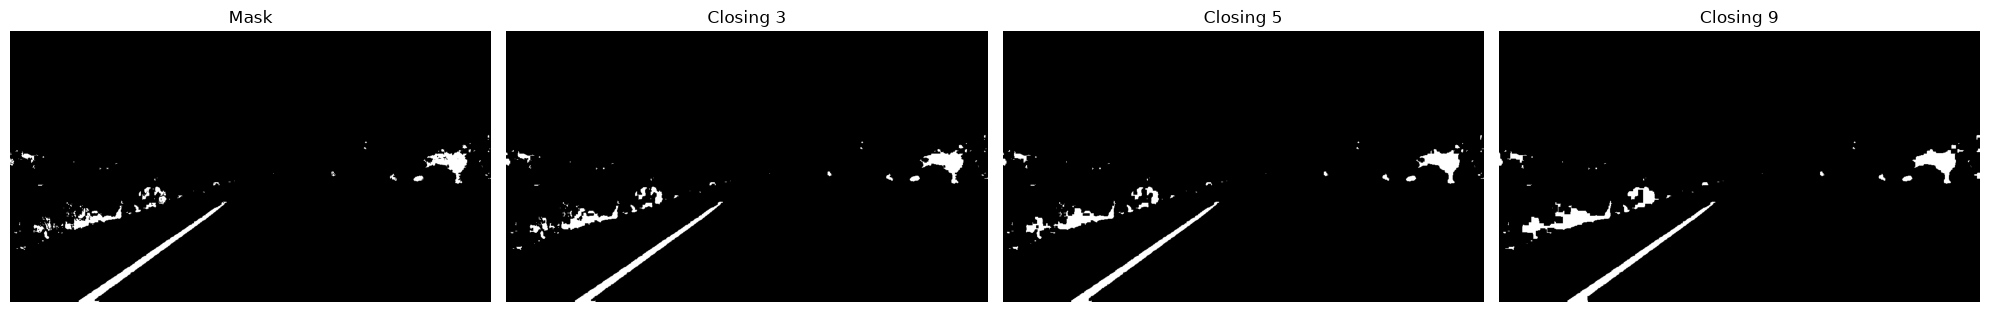

In [9]:
img=read('02_solidYellowLeft_yellow_white.jpg')
m=cv2.inRange(cv2.cvtColor(img,cv2.COLOR_BGR2HSV),(15,70,70),(40,255,255))
view([('Mask',m)]+[(f'Closing {k}',cv2.morphologyEx(m,cv2.MORPH_CLOSE,cv2.getStructuringElement(cv2.MORPH_RECT,(k,k)))) for k in (3,5,9)])

## 05 · 探索实验五：透视变换
没有相机标定时只能得到近似鸟瞰图，不能报告米制距离。

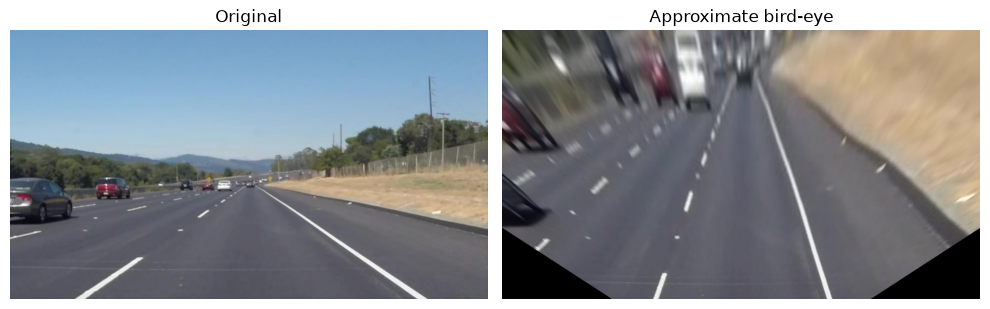

In [10]:
img=read('01_solidWhiteRight_straight_white.jpg')
h,w=img.shape[:2]
src=np.float32([[.39*w,.56*h],[.61*w,.56*h],[.96*w,.97*h],[.04*w,.97*h]])
dst=np.float32([[.25*w,0],[.75*w,0],[.75*w,h-1],[.25*w,h-1]])
bird=cv2.warpPerspective(img,cv2.getPerspectiveTransform(src,dst),(w,h))
view([('Original',img),('Approximate bird-eye',bird)])


### 探索任务 5 · 透视变换实验 Cell
先预测：梯形顶边上移或下移，鸟瞰结果会怎样改变？
1. 修改顶部位置 0.50、0.56、0.62。
2. 比较畸变程度与视觉车道宽度。
3. 说明相机标定为何必要。

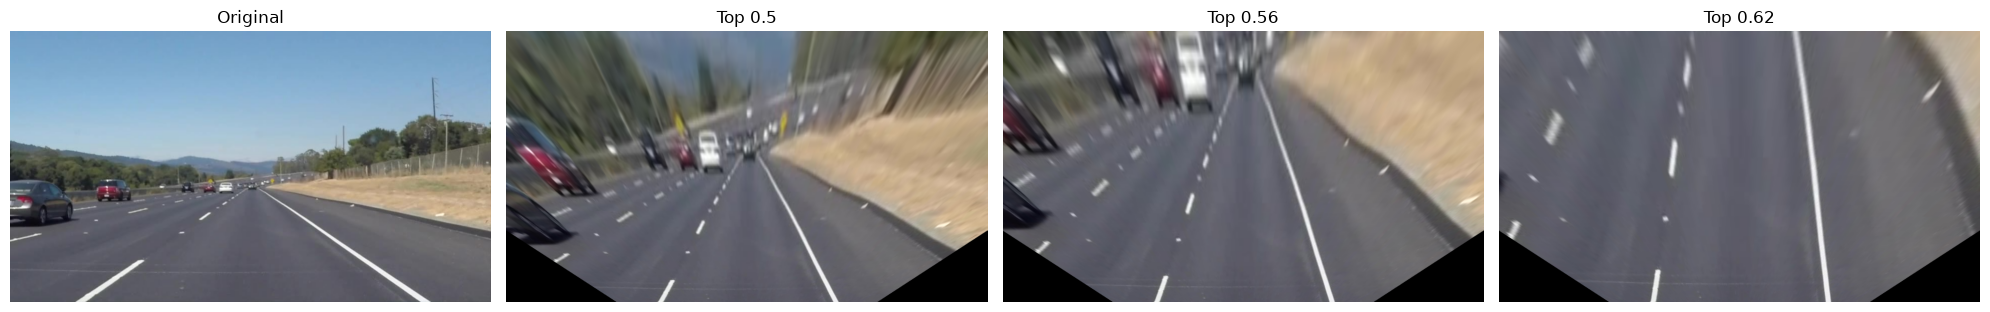

In [11]:
img=read('01_solidWhiteRight_straight_white.jpg')
h,w=img.shape[:2]
results=[('Original',img)]
for top in (.50,.56,.62):
    src=np.float32([[.39*w,top*h],[.61*w,top*h],[.96*w,.97*h],[.04*w,.97*h]])
    dst=np.float32([[.25*w,0],[.75*w,0],[.75*w,h-1],[.25*w,h-1]])
    results.append((f'Top {top}',cv2.warpPerspective(img,cv2.getPerspectiveTransform(src,dst),(w,h))))
view(results)

## 总结与进一步探索
1. 哪种参数变化产生了你未预期的输出？
2. 哪些结论只在当前素材成立？
3. 选择一个失败案例并说明可能的算法改进方向。